In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
...

Ellipsis

In [2]:
df = pd.read_csv(r"C:\Users\LUXE TECH\Desktop\Detection-fraud\fraudTest_senegal.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (555719, 24)


,id,date_transaction,num_carte,commercant,categorie,montant_fcfa,prenom,nom,genre,rue,...,longitude_client,population_ville,profession,date_naissance,num_transaction,temps_unix,latitude_commercant,longitude_commercant,est_fraude,pays
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,soins_personnels,1601.6,Aminata,Kane,M,351 Darlene Green,...,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0,Sénégal
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,soins_personnels,16710.4,Aïssatou,Ly,F,3638 Marsh Union,...,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0,Sénégal
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",sante_sport,23116.8,Khady,Sall,F,9333 Valentine Point,...,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0,Sénégal
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,divers,33628.0,Ramatoulaye,Cissé,M,32941 Krystal Mill Apt. 552,...,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0,Sénégal
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,voyage,1786.4,Cheikh,Ly,M,5783 Evan Roads Apt. 465,...,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0,Sénégal


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555719 entries, 0 to 555718
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    555719 non-null  int64  
 1   date_transaction      555719 non-null  object 
 2   num_carte             555719 non-null  int64  
 3   commercant            555719 non-null  object 
 4   categorie             555719 non-null  object 
 5   montant_fcfa          555719 non-null  float64
 6   prenom                555719 non-null  object 
 7   nom                   555719 non-null  object 
 8   genre                 555719 non-null  object 
 9   rue                   555719 non-null  object 
 10  ville                 555719 non-null  object 
 11  region                555719 non-null  object 
 12  code_postal           555719 non-null  int64  
 13  latitude_client       555719 non-null  float64
 14  longitude_client      555719 non-null  float64
 15  

In [4]:
df.isnull().sum()


id                      0
date_transaction        0
num_carte               0
commercant              0
categorie               0
montant_fcfa            0
prenom                  0
nom                     0
genre                   0
rue                     0
ville                   0
region                  0
code_postal             0
latitude_client         0
longitude_client        0
population_ville        0
profession              0
date_naissance          0
num_transaction         0
temps_unix              0
latitude_commercant     0
longitude_commercant    0
est_fraude              0
pays                    0
dtype: int64

In [5]:
df.describe()

,id,num_carte,montant_fcfa,code_postal,latitude_client,longitude_client,population_ville,temps_unix,latitude_commercant,longitude_commercant,est_fraude
count,555719.000000,5.557190e+05,5.557190e+05,555719.000000,555719.000000,555719.000000,5.557190e+05,5.557190e+05,555719.000000,555719.000000,555719.000000
mean,277859.000000,4.178387e+17,3.885997e+04,48842.628015,38.543253,-90.231325,8.822189e+04,1.380679e+09,38.542798,-90.231380,0.003860
std,160422.401459,1.309837e+18,8.777773e+04,26855.283328,5.061336,13.721780,3.003909e+05,5.201104e+06,5.095829,13.733071,0.062008
min,0.000000,6.041621e+10,5.600000e+02,1257.000000,20.027100,-165.672300,2.300000e+01,1.371817e+09,19.027422,-166.671575,0.000000
25%,138929.500000,1.800429e+14,5.392800e+03,26292.000000,34.668900,-96.798000,7.410000e+02,1.376029e+09,34.755302,-96.905129,0.000000
50%,277859.000000,3.521417e+15,2.648240e+04,48174.000000,39.371600,-87.476900,2.408000e+03,1.380762e+09,39.376593,-87.445204,0.000000
75%,416788.500000,4.635331e+15,4.648560e+04,72011.000000,41.894800,-80.175200,1.968500e+04,1.385867e+09,41.954163,-80.264637,0.000000
max,555718.000000,4.992346e+18,1.275014e+07,99921.000000,65.689900,-67.950300,2.906700e+06,1.388534e+09,66.679297,-66.952026,1.000000


est_fraude
0    553574
1      2145
Name: count, dtype: int64

est_fraude
0    99.614
1     0.386
Name: proportion, dtype: float64


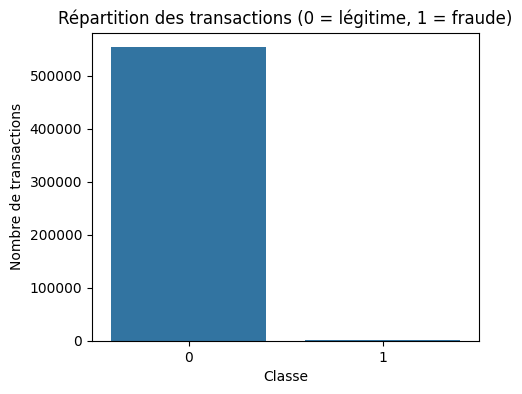

In [6]:
fraud_counts = df['est_fraude'].value_counts()
fraud_pct = df['est_fraude'].value_counts(normalize=True) * 100

print(fraud_counts)
print()
print(fraud_pct.round(3))

plt.figure(figsize=(5,4))
sns.countplot(x='est_fraude', data=df)
plt.title("Répartition des transactions (0 = légitime, 1 = fraude)")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")
plt.show()

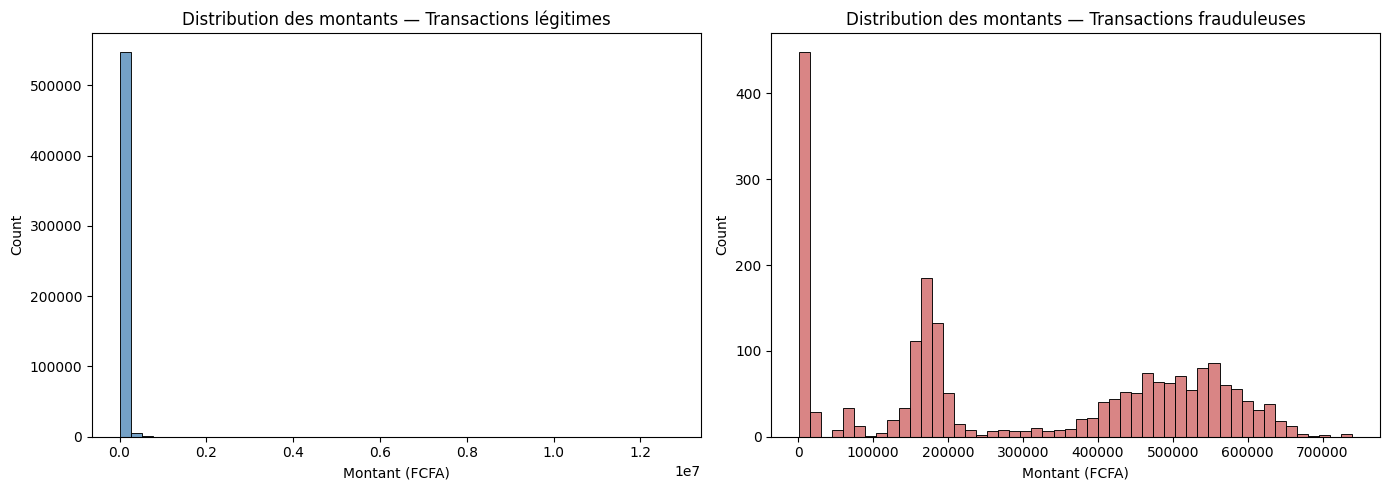

,count,mean,std,min,25%,50%,75%,max
est_fraude,,,,,,,,
0,553574.0,37864.068617,85384.281174,560.0,5376.0,26404.0,46267.2,12750141.6
1,2145.0,295879.636737,219938.652549,996.8,120125.6,208286.4,508351.2,739715.2


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.histplot(df[df['est_fraude']==0]['montant_fcfa'], bins=50, ax=axes[0], color='steelblue')
axes[0].set_title("Distribution des montants — Transactions légitimes")
axes[0].set_xlabel("Montant (FCFA)")

sns.histplot(df[df['est_fraude']==1]['montant_fcfa'], bins=50, ax=axes[1], color='indianred')
axes[1].set_title("Distribution des montants — Transactions frauduleuses")
axes[1].set_xlabel("Montant (FCFA)")

plt.tight_layout()
plt.show()

df.groupby('est_fraude')['montant_fcfa'].describe()

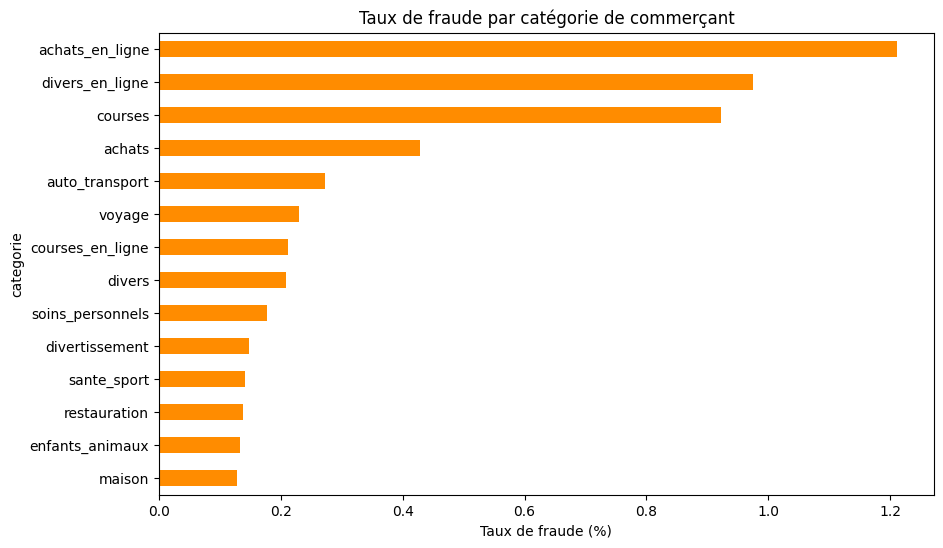

categorie
achats_en_ligne     1.211135
divers_en_ligne     0.975628
courses             0.922878
achats              0.427788
auto_transport      0.273195
voyage              0.229239
courses_en_ligne    0.211057
divers              0.208249
soins_personnels    0.177995
divertissement      0.147117
sante_sport         0.141790
restauration        0.137517
enfants_animaux     0.133492
maison              0.127997
Name: est_fraude, dtype: float64

In [8]:
fraud_rate_by_cat = df.groupby('categorie')['est_fraude'].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10,6))
fraud_rate_by_cat.plot(kind='barh', color='darkorange')
plt.xlabel("Taux de fraude (%)")
plt.title("Taux de fraude par catégorie de commerçant")
plt.gca().invert_yaxis()
plt.show()

fraud_rate_by_cat

In [9]:
df['date_transaction'] = pd.to_datetime(df['date_transaction'])
df['date_naissance'] = pd.to_datetime(df['date_naissance'])

# Âge du client au moment de la transaction
df['age_client'] = (df['date_transaction'] - df['date_naissance']).dt.days // 365

# Heure et jour de la semaine
df['heure_transaction'] = df['date_transaction'].dt.hour
df['jour_semaine'] = df['date_transaction'].dt.dayofweek  # 0 = lundi
df['est_weekend'] = df['jour_semaine'].isin([5,6]).astype(int)

df[['date_transaction','age_client','heure_transaction','jour_semaine','est_weekend']].head()

,date_transaction,age_client,heure_transaction,jour_semaine,est_weekend
0,2020-06-21 12:14:25,52,12,6,1
1,2020-06-21 12:14:33,30,12,6,1
2,2020-06-21 12:14:53,49,12,6,1
3,2020-06-21 12:15:15,32,12,6,1
4,2020-06-21 12:15:17,65,12,6,1


In [10]:
def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    r_terre_km = 6371
    return c * r_terre_km

df['distance_client_commercant_km'] = haversine_distance(
    df['latitude_client'], df['longitude_client'],
    df['latitude_commercant'], df['longitude_commercant']
)

df[['distance_client_commercant_km']].describe()

,distance_client_commercant_km
count,555719.000000
mean,76.104902
std,29.117079
min,0.123883
25%,55.286255
50%,78.179517
75%,98.520760
max,150.922504


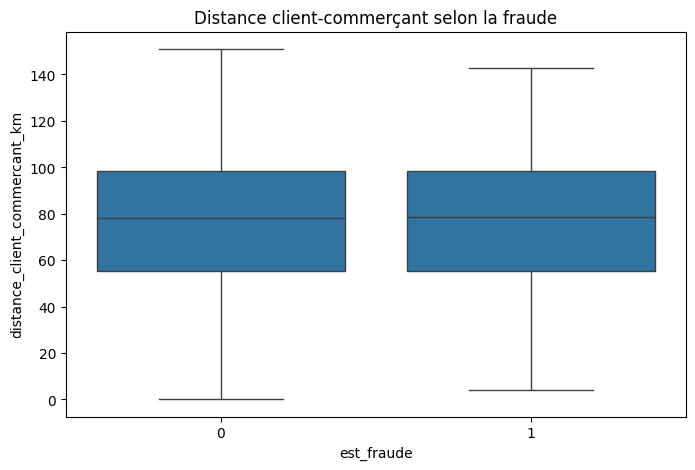

In [11]:
plt.figure(figsize=(8,5))
sns.boxplot(x='est_fraude', y='distance_client_commercant_km', data=df, showfliers=False)
plt.title("Distance client-commerçant selon la fraude")
plt.show()

In [12]:
colonnes_a_supprimer = [
    'id', 'num_carte', 'num_transaction', 'prenom', 'nom', 'rue',
    'date_transaction', 'date_naissance', 'temps_unix', 'pays',
    'code_postal', 'latitude_client', 'longitude_client',
    'latitude_commercant', 'longitude_commercant'
]

df_model = df.drop(columns=colonnes_a_supprimer)
df_model.head()

,commercant,categorie,montant_fcfa,genre,ville,region,population_ville,profession,est_fraude,age_client,heure_transaction,jour_semaine,est_weekend,distance_client_commercant_km
0,fraud_Kirlin and Sons,soins_personnels,1601.6,M,Kaffrine,Kaolack,333497,Mechanical engineer,0,52,12,6,1,24.561462
1,fraud_Sporer-Keebler,soins_personnels,16710.4,F,Dagana,Saint-Louis,302,"Sales professional, IT",0,30,12,6,1,104.925092
2,"fraud_Swaniawski, Nitzsche and Welch",sante_sport,23116.8,F,Ranérou,Matam,34496,"Librarian, public",0,49,12,6,1,59.080078
3,fraud_Haley Group,divers,33628.0,M,Kanel,Matam,54767,Set designer,0,32,12,6,1,27.698567
4,fraud_Johnston-Casper,voyage,1786.4,M,Sébikotane,Thiès,1126,Furniture designer,0,65,12,6,1,104.335106


In [13]:
print("Modalités uniques par colonne catégorielle :")
for c in ['genre','categorie','region','ville','profession','commercant']:
    print(f"  {c}: {df_model[c].nunique()}")

Modalités uniques par colonne catégorielle :
  genre: 2
  categorie: 14
  region: 12
  ville: 43
  profession: 478
  commercant: 693


In [14]:
# Encodage binaire du genre
df_model['genre'] = df_model['genre'].map({'M': 0, 'F': 1})

# One-Hot Encoding pour categorie et region (peu de modalités)
df_model = pd.get_dummies(df_model, columns=['categorie', 'region'], drop_first=True)

# Frequency encoding pour les colonnes à forte cardinalité
for col in ['commercant', 'ville', 'profession']:
    freq = df_model[col].value_counts(normalize=True)
    df_model[col + '_freq'] = df_model[col].map(freq)
    df_model.drop(columns=[col], inplace=True)

print("Dimensions après encodage :", df_model.shape)
df_model.head()

Dimensions après encodage : (555719, 36)


,montant_fcfa,genre,population_ville,est_fraude,age_client,heure_transaction,jour_semaine,est_weekend,distance_client_commercant_km,categorie_achats_en_ligne,...,region_Louga,region_Matam,region_Saint-Louis,region_Sédhiou,region_Tambacounda,region_Thiès,region_Ziguinchor,commercant_freq,ville_freq,profession_freq
0,1601.6,0,333497,0,52,12,6,1,24.561462,False,...,False,False,False,False,False,False,False,0.001324,0.023021,0.004373
1,16710.4,1,302,0,30,12,6,1,104.925092,False,...,False,False,True,False,False,False,False,0.001413,0.022983,0.004562
2,23116.8,1,34496,0,49,12,6,1,59.080078,False,...,False,True,False,False,False,False,False,0.001359,0.023190,0.004655
3,33628.0,0,54767,0,32,12,6,1,27.698567,False,...,False,True,False,False,False,False,False,0.001279,0.023001,0.001193
4,1786.4,0,1126,0,65,12,6,1,104.335106,False,...,False,False,False,False,False,True,False,0.000666,0.023197,0.001603


In [15]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=['est_fraude'])
y = df_model['est_fraude']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train :", X_train.shape, " | Taux de fraude :", y_train.mean().round(4))
print("Test  :", X_test.shape,  " | Taux de fraude :", y_test.mean().round(4))

Train : (444575, 35)  | Taux de fraude : 0.0039
Test  : (111144, 35)  | Taux de fraude : 0.0039


In [16]:
from sklearn.preprocessing import StandardScaler

colonnes_numeriques = ['montant_fcfa', 'age_client', 'distance_client_commercant_km',
                        'population_ville', 'commercant_freq', 'ville_freq', 'profession_freq']

scaler = StandardScaler()
X_train[colonnes_numeriques] = scaler.fit_transform(X_train[colonnes_numeriques])
X_test[colonnes_numeriques] = scaler.transform(X_test[colonnes_numeriques])

X_train[colonnes_numeriques].describe()

,montant_fcfa,age_client,distance_client_commercant_km,population_ville,commercant_freq,ville_freq,profession_freq
count,4.445750e+05,4.445750e+05,4.445750e+05,4.445750e+05,4.445750e+05,4.445750e+05,4.445750e+05
mean,-5.638632e-17,-1.631335e-16,-4.551181e-16,1.304173e-17,-1.212753e-16,-4.617069e-14,-9.210085e-16
std,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00
min,-4.438252e-01,-1.801509e+00,-2.609259e+00,-2.932160e-01,-2.530520e+00,-1.637363e+00,-1.946910e+00
25%,-3.877471e-01,-7.696296e-01,-7.148326e-01,-2.908221e-01,-5.386894e-01,-6.676237e-01,-7.205044e-01
50%,-1.431194e-01,-1.390365e-01,7.179610e-02,-2.852641e-01,-7.054300e-02,-1.299467e-01,-1.663077e-01
75%,8.839742e-02,6.635364e-01,7.694040e-01,-2.276600e-01,7.244225e-01,4.557372e-01,7.662237e-01
max,1.386916e+02,2.841949e+00,2.496812e+00,9.398081e+00,4.337099e+00,2.347208e+00,2.809462e+00


In [17]:
import joblib

X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)
joblib.dump(scaler, "scaler.joblib")

print("Fichiers sauvegardés avec succès.")

Fichiers sauvegardés avec succès.


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
    precision_recall_curve
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)
%matplotlib inline

In [19]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze()
y_test = pd.read_csv("y_test.csv").squeeze()
scaler = joblib.load("scaler.joblib")

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Taux de fraude train :", y_train.mean().round(4), "| test :", y_test.mean().round(4))

Train : (444575, 35) | Test : (111144, 35)
Taux de fraude train : 0.0039 | test : 0.0039


In [20]:
def evaluer_modele(nom, model, X_test, y_test, y_pred, y_proba):
    print(f"===== {nom} =====")
    print(classification_report(y_test, y_pred, target_names=['Légitime', 'Fraude'], digits=3))

    roc_auc = roc_auc_score(y_test, y_proba)
    print(f"ROC-AUC : {roc_auc:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(12,4.5))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Légitime', 'Fraude'])
    disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f"Matrice de confusion — {nom}")

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    axes[1].plot([0,1],[0,1],'k--', alpha=0.3)
    axes[1].set_xlabel("Taux de faux positifs")
    axes[1].set_ylabel("Taux de vrais positifs")
    axes[1].set_title(f"Courbe ROC — {nom}")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    return {
        'modele': nom,
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc
    }

resultats = []

===== Régression Logistique (baseline, sans SMOTE) =====
              precision    recall  f1-score   support

    Légitime      0.996     1.000     0.998    110715
      Fraude      0.000     0.000     0.000       429

    accuracy                          0.996    111144
   macro avg      0.498     0.500     0.499    111144
weighted avg      0.992     0.996     0.994    111144

ROC-AUC : 0.8079


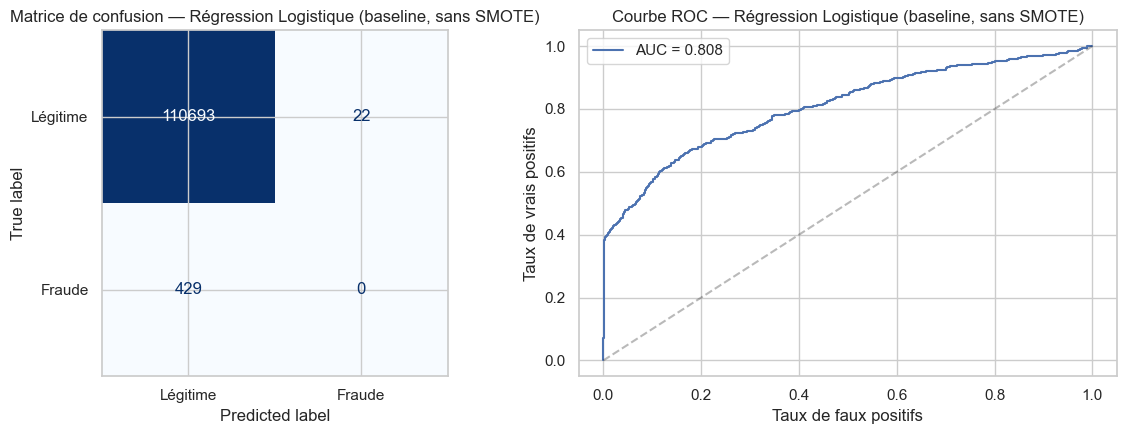

In [21]:
log_reg_base = LogisticRegression(max_iter=1000, random_state=42)
log_reg_base.fit(X_train, y_train)

y_pred_base = log_reg_base.predict(X_test)
y_proba_base = log_reg_base.predict_proba(X_test)[:,1]

res = evaluer_modele("Régression Logistique (baseline, sans SMOTE)", log_reg_base, X_test, y_test, y_pred_base, y_proba_base)
resultats.append(res)

In [22]:
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Avant SMOTE :", y_train.value_counts().to_dict())
print("Après SMOTE :", y_train_sm.value_counts().to_dict())

Avant SMOTE : {0: 442859, 1: 1716}
Après SMOTE : {0: 442859, 1: 442859}


===== Régression Logistique (avec SMOTE) =====
              precision    recall  f1-score   support

    Légitime      0.999     0.977     0.988    110715
      Fraude      0.101     0.681     0.176       429

    accuracy                          0.975    111144
   macro avg      0.550     0.829     0.582    111144
weighted avg      0.995     0.975     0.984    111144

ROC-AUC : 0.8745


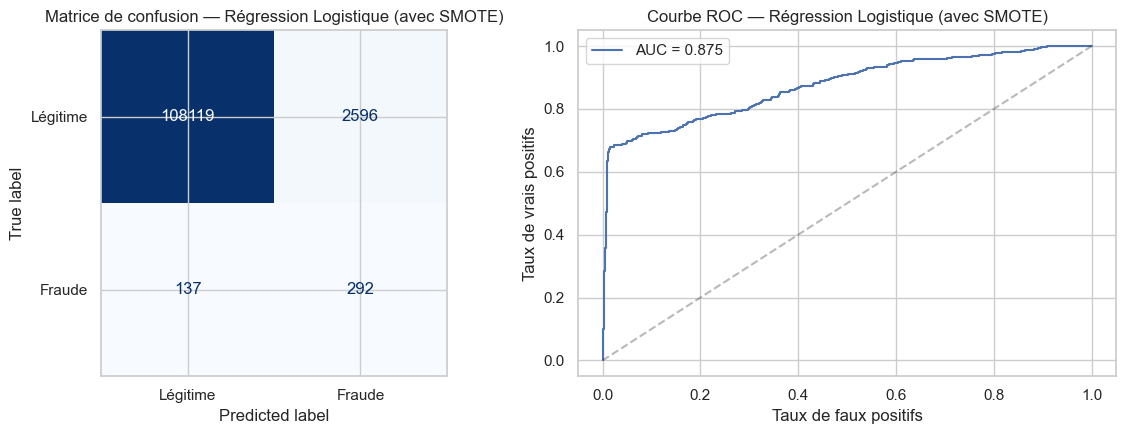

In [23]:
log_reg_sm = LogisticRegression(max_iter=1000, random_state=42)
log_reg_sm.fit(X_train_sm, y_train_sm)

y_pred_sm = log_reg_sm.predict(X_test)
y_proba_sm = log_reg_sm.predict_proba(X_test)[:,1]

res = evaluer_modele("Régression Logistique (avec SMOTE)", log_reg_sm, X_test, y_test, y_pred_sm, y_proba_sm)
resultats.append(res)

===== Random Forest (avec SMOTE) =====
              precision    recall  f1-score   support

    Légitime      1.000     0.989     0.994    110715
      Fraude      0.235     0.876     0.371       429

    accuracy                          0.989    111144
   macro avg      0.617     0.933     0.683    111144
weighted avg      0.997     0.989     0.992    111144

ROC-AUC : 0.9873


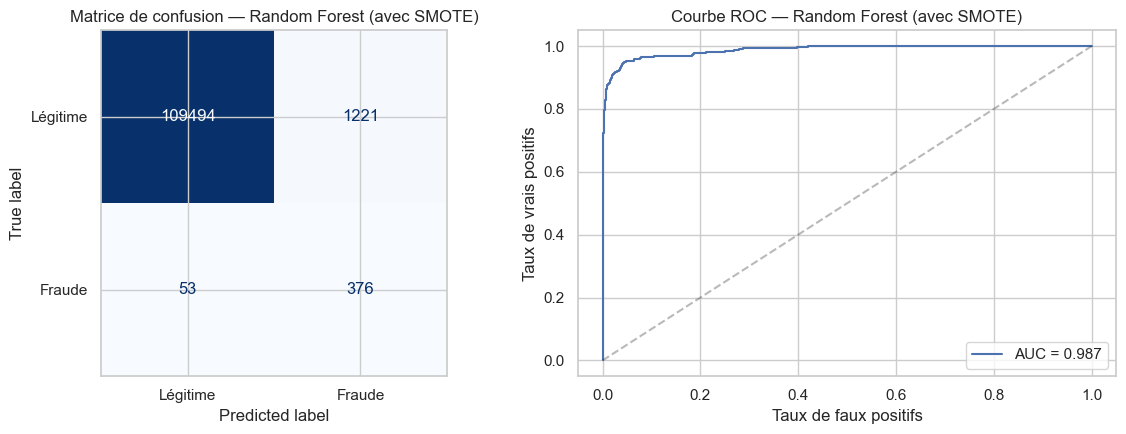

In [24]:
rf = RandomForestClassifier(
    n_estimators=200, max_depth=12, class_weight='balanced',
    random_state=42, n_jobs=-1
)
rf.fit(X_train_sm, y_train_sm)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:,1]

res = evaluer_modele("Random Forest (avec SMOTE)", rf, X_test, y_test, y_pred_rf, y_proba_rf)
resultats.append(res)

===== XGBoost (avec SMOTE) =====
              precision    recall  f1-score   support

    Légitime      0.999     0.999     0.999    110715
      Fraude      0.704     0.821     0.758       429

    accuracy                          0.998    111144
   macro avg      0.852     0.910     0.878    111144
weighted avg      0.998     0.998     0.998    111144

ROC-AUC : 0.9954


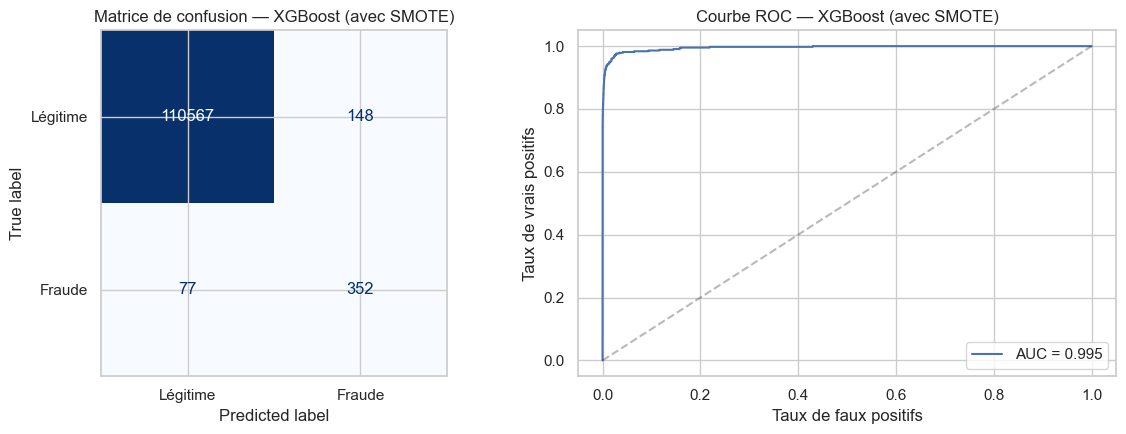

In [25]:
xgb = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    eval_metric='logloss', random_state=42, n_jobs=-1
)
xgb.fit(X_train_sm, y_train_sm)

y_pred_xgb = xgb.predict(X_test)
y_proba_xgb = xgb.predict_proba(X_test)[:,1]

res = evaluer_modele("XGBoost (avec SMOTE)", xgb, X_test, y_test, y_pred_xgb, y_proba_xgb)
resultats.append(res)

                                              precision  recall      f1  \
modele                                                                    
Random Forest (avec SMOTE)                       0.2354  0.8765  0.3712   
XGBoost (avec SMOTE)                             0.7040  0.8205  0.7578   
Régression Logistique (avec SMOTE)               0.1011  0.6807  0.1761   
Régression Logistique (baseline, sans SMOTE)     0.0000  0.0000  0.0000   

                                              roc_auc  
modele                                                 
Random Forest (avec SMOTE)                     0.9873  
XGBoost (avec SMOTE)                           0.9954  
Régression Logistique (avec SMOTE)             0.8745  
Régression Logistique (baseline, sans SMOTE)   0.8079  


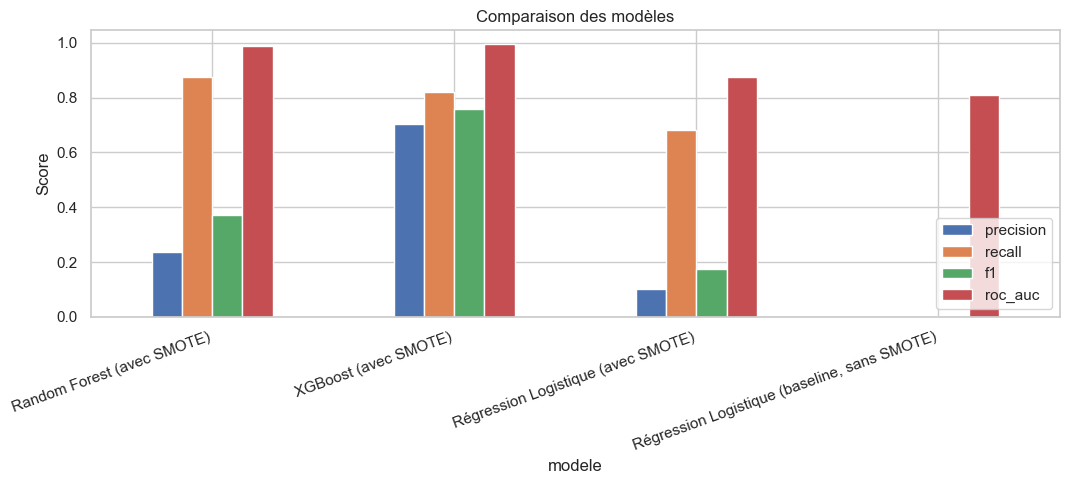

In [26]:
df_resultats = pd.DataFrame(resultats).set_index('modele')
df_resultats = df_resultats.sort_values('recall', ascending=False)
print(df_resultats.round(4))

df_resultats[['precision','recall','f1','roc_auc']].plot(kind='bar', figsize=(11,5))
plt.title("Comparaison des modèles")
plt.ylabel("Score")
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [28]:
param_dist = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=15,
    scoring='recall',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_sm, y_train_sm)

print("Meilleurs paramètres :", random_search.best_params_)
print("Meilleur score (recall CV) :", random_search.best_score_.round(4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Meilleurs paramètres : {'subsample': 1.0, 'n_estimators': 300, 'max_depth': 10, 'learning_rate': 0.2, 'colsample_bytree': 0.8}
Meilleur score (recall CV) : 0.9998


===== XGBoost optimisé =====
              precision    recall  f1-score   support

    Légitime      0.999     1.000     0.999    110715
      Fraude      0.900     0.800     0.847       429

    accuracy                          0.999    111144
   macro avg      0.950     0.900     0.923    111144
weighted avg      0.999     0.999     0.999    111144

ROC-AUC : 0.9933


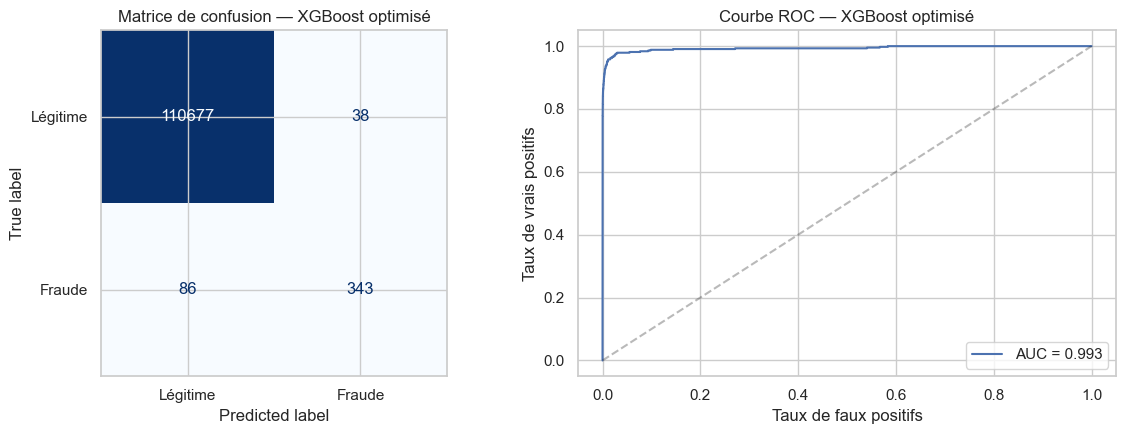

In [31]:
best_model = random_search.best_estimator_

y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:,1]

res = evaluer_modele("XGBoost optimisé", best_model, X_test, y_test, y_pred_best, y_proba_best)
resultats.append(res)

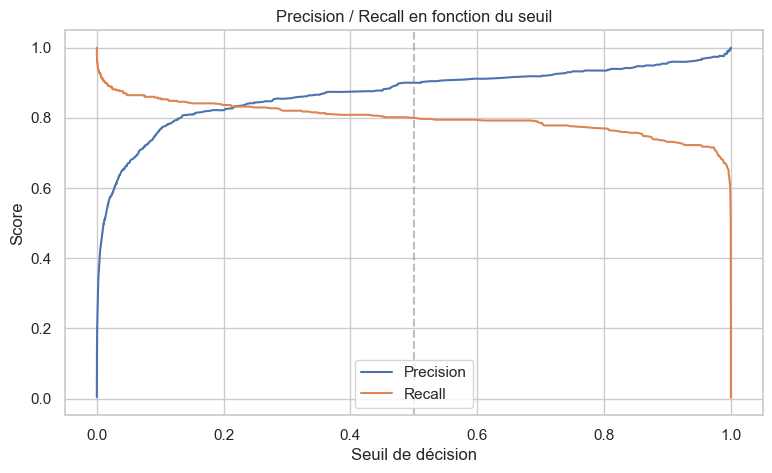

In [34]:
precisions, recalls, seuils = precision_recall_curve(y_test, y_proba_best)

plt.figure(figsize=(9,5))
plt.plot(seuils, precisions[:-1], label='Precision')
plt.plot(seuils, recalls[:-1], label='Recall')
plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Precision / Recall en fonction du seuil")
plt.legend()
plt.axvline(0.5, color='gray', linestyle='--', alpha=0.5, label='Seuil par défaut (0.5)')
plt.show()

In [35]:
seuil_cible_recall = 0.85
idx = np.argmin(np.abs(recalls[:-1] - seuil_cible_recall))
seuil_choisi = seuils[idx]

print(f"Pour viser un Recall ≈ {seuil_cible_recall}, seuil recommandé ≈ {seuil_choisi:.3f}")
print(f"Precision correspondante : {precisions[idx]:.3f}")

y_pred_seuil = (y_proba_best >= seuil_choisi).astype(int)
print()
print(classification_report(y_test, y_pred_seuil, target_names=['Légitime', 'Fraude'], digits=3))

Pour viser un Recall ≈ 0.85, seuil recommandé ≈ 0.113
Precision correspondante : 0.782

              precision    recall  f1-score   support

    Légitime      0.999     0.999     0.999    110715
      Fraude      0.782     0.851     0.815       429

    accuracy                          0.999    111144
   macro avg      0.891     0.925     0.907    111144
weighted avg      0.999     0.999     0.999    111144



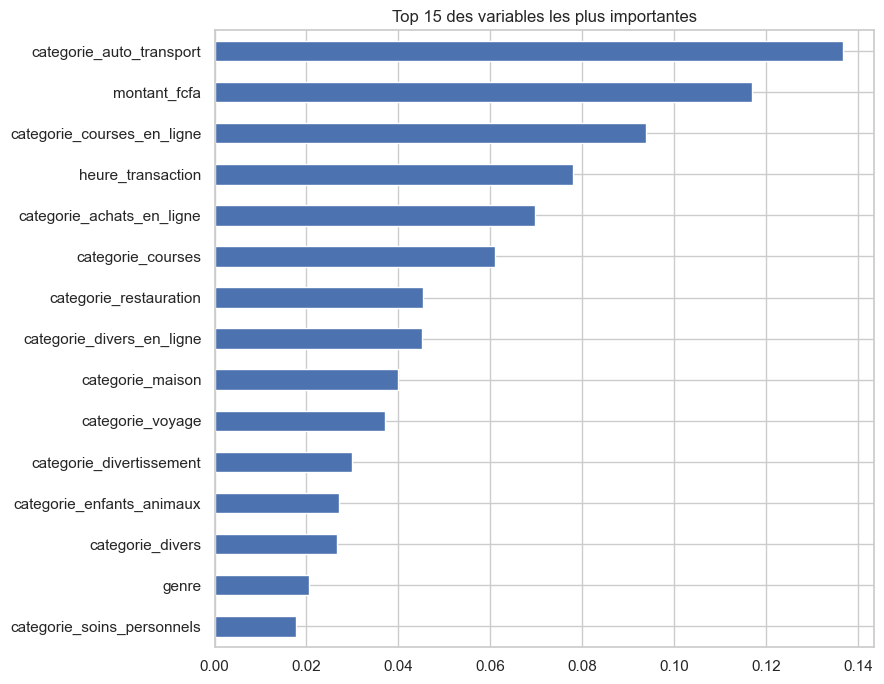

categorie_auto_transport      0.136663
montant_fcfa                  0.116913
categorie_courses_en_ligne    0.093960
heure_transaction             0.078073
categorie_achats_en_ligne     0.069634
categorie_courses             0.061105
categorie_restauration        0.045346
categorie_divers_en_ligne     0.045076
categorie_maison              0.039933
categorie_voyage              0.037040
categorie_divertissement      0.029982
categorie_enfants_animaux     0.026972
categorie_divers              0.026570
genre                         0.020650
categorie_soins_personnels    0.017688
dtype: float32

In [36]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(9,7))
importances.head(15).plot(kind='barh')
plt.title("Top 15 des variables les plus importantes")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

importances.head(15)

In [37]:
joblib.dump(best_model, "modele_fraude_final.joblib")
joblib.dump(scaler, "scaler_final.joblib")
joblib.dump(list(X_train.columns), "colonnes_modele.joblib")
joblib.dump(seuil_choisi, "seuil_decision.joblib")

print("Pipeline exporté avec succès :")
print(" - modele_fraude_final.joblib")
print(" - scaler_final.joblib")
print(" - colonnes_modele.joblib")
print(" - seuil_decision.joblib")

Pipeline exporté avec succès :
 - modele_fraude_final.joblib
 - scaler_final.joblib
 - colonnes_modele.joblib
 - seuil_decision.joblib
